# Parte 2 · Evaluación: ¿qué tan bien leen y escuchan los modelos?

Se compara cada modelo **contra transcripciones hechas a mano** por el estudiante, sobre la **misma muestra**
para todos los modelos. La muestra y todas las configuraciones se fijaron y se commitearon **antes** de ver
resultados y antes de escribir las referencias (`modelos/config_evaluacion.json`, commit `4045a71`).

| | Base | Alternativo |
|---|---|---|
| **OCR** | PaddleOCR 3.7.0 (`lang='es'`) | Tesseract 5.4.0 (`spa`, `--oem 3 --psm 3`) |
| **ASR** | faster-whisper small (CPU, int8) | Parakeet TDT 0.6B v3 (CPU) |
| **LLM** | Gemini `gemini-3.8-flash`, temperature 0, JSON con esquema, solo texto seudonimizado | — (auditoría humana de 20 casos) |

**Este notebook funciona con lo que haya.** Cada sección revisa primero si existen las referencias
manuales o las salidas que necesita; si faltan, lo dice explícitamente y no inventa el resultado.

In [1]:
import sys, json, warnings
from datetime import datetime
from importlib.metadata import version
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio

warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
import parte2
from evaluacion import tasa

RAW = Path("datos/raw")
CONFIG = json.loads(Path("modelos/config_evaluacion.json").read_text(encoding="utf-8"))
print("Ejecutado:", datetime.now().strftime("%d/%m/%Y %H:%M"))
for p in ["jiwer", "pandas", "plotly"]:
    print(f"  {p:8s} {version(p)}")
print("Semilla:", CONFIG["semilla"])
print("Regla de no ajuste:", CONFIG["metricas"]["regla_de_no_ajuste"])

Ejecutado: 25/10/2026 23:46
  jiwer    4.0.0
  pandas   2.3.3
  plotly   7.1.0
Semilla: 2026
Regla de no ajuste: Ninguna configuración se cambia después de ver las métricas. Si un modelo falla técnicamente, se reporta el fallo; no se reemplaza por otra configuración.


In [2]:
CREMA, CARBON, VERDE_TITULO, VERDE, MORADO = "#F7F3EA", "#2B2B2B", "#1F5F4A", "#0F7A55", "#6A4C93"
pio.templates["propia"] = pio.templates["plotly_white"]
pio.templates["propia"].layout.update(
    paper_bgcolor=CREMA, plot_bgcolor=CREMA, font=dict(family="Segoe UI, Arial", color=CARBON, size=13),
    title=dict(font=dict(color=VERDE_TITULO, size=17), x=0.01, xanchor="left"),
    xaxis=dict(gridcolor="#E4DED0", zeroline=False), yaxis=dict(gridcolor="#E4DED0", zeroline=False),
    margin=dict(l=70, r=30, t=90, b=60))
pio.templates.default = "propia"
pio.renderers.default = "plotly_mimetype+png"
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
def mostrar(fig, nombre, alto=440):
    fig.update_layout(height=alto, width=980)
    fig.write_html(FIG / f"{nombre}.html", include_plotlyjs="cdn")
    fig.show()

## 1. Estado: qué hay y qué falta

Las referencias manuales viven en `datos/raw/referencias/` (fuera de Git: al transcribir se escriben nombres
reales). Se publican solo las métricas.

In [3]:
ref_audio, falta_audio = parte2.referencias("audio")
ref_docs, falta_docs = parte2.referencias("documentos")
salidas_aud = parte2.salidas_audio()
salidas_doc = parte2.salidas_documentos()
pk = salidas_aud.get("Parakeet TDT 0.6B v3 (alternativo)")
auditoria = RAW / "referencias" / "auditoria_llm.xlsx"
aud = pd.read_excel(auditoria) if auditoria.exists() else None
aud_hechas = 0 if aud is None else int(aud["completamente_correcta"].fillna("").astype(str).str.strip().ne("").sum())
muestra_aud = parte2.muestra("audio")

estado = pd.DataFrame([
    ("Referencias manuales de audio", f"{10 - len(falta_audio)} de 10"),
    ("Referencias manuales de documentos", f"{0 if ref_docs is None else len(ref_docs)} de 10"
),
    ("Parakeet sobre la muestra de audio", f"{0 if pk is None else pk['id'].isin(muestra_aud['id']).sum()} de 10"),
    ("Parakeet sobre todo el corpus", f"{0 if pk is None else len(pk)} de {len(salidas_aud['faster-whisper small (base)'])}"),
    ("Tesseract sobre todo el corpus", f"{len(salidas_doc['Tesseract (alternativo)'])} de {len(salidas_doc['PaddleOCR (base)'])}"),
    ("Extracciones del LLM", f"{len(list((RAW / 'llm').glob('*.json')))} de 54 (19 documentos + 35 audios)"),
    ("Auditoría humana del LLM", f"{aud_hechas} de 20"),
], columns=["pieza", "estado"])
estado

,pieza,estado
0,Referencias manuales de audio,10 de 10
1,Referencias manuales de documentos,0 de 10
2,Parakeet sobre la muestra de audio,10 de 10
3,Parakeet sobre todo el corpus,35 de 35
4,Tesseract sobre todo el corpus,19 de 19
5,Extracciones del LLM,32 de 54 (19 documentos + 35 audios)
6,Auditoría humana del LLM,19 de 20


## 2. ASR: WER y CER contra la referencia manual

Misma normalización para la referencia y para cada modelo (`voz.normalizar`: minúsculas, sin puntuación, con
tildes); las marcas `[HABLANTE_n]` se quitan. El valor **agregado** suma los errores de todos los clips y
divide entre todas las palabras (o caracteres) de las referencias, así que pesan más los clips largos.
Un modelo solo se evalúa si tiene salida para **todos** los clips con referencia.

In [4]:
metricas, detalle_asr = [], pd.DataFrame()
if ref_audio is None or ref_audio.empty:
    print("PENDIENTE: todavía no hay referencias manuales de audio. No se calcula WER/CER.")
else:
    if falta_audio:
        print(f"AVISO: se evalúa con {len(ref_audio)} de 10 clips; faltan referencias para {falta_audio}.")
    for m in ["WER", "CER"]:
        res, det = parte2.evaluar(ref_audio, salidas_aud, m, por="tipo")
        metricas.append(res.assign(modalidad="audio"))
        if m == "WER":
            detalle_asr = det
    display(pd.concat(metricas, ignore_index=True).pivot_table(index=["modelo", "grupo"], columns="metrica", values="valor").round(3))

metrica                                               CER    WER
modelo                             grupo                        
Parakeet TDT 0.6B v3 (alternativo) TODOS            0.213  0.286
                                   calle            0.151  0.253
                                   evento_publico   0.066  0.133
                                   fiesta_patronal  0.691  0.728
                                   leido_estudio    0.075  0.130
                                   marcha           0.347  0.391
faster-whisper small (base)        TODOS            0.219  0.302
                                   calle            0.153  0.240
                                   evento_publico   0.097  0.176
                                   fiesta_patronal  0.696  0.743
                                   leido_estudio    0.104  0.174
                                   marcha           0.233  0.385

In [5]:
if not detalle_asr.empty:
    tabla = detalle_asr[["id", "tipo", "duracion_seg", "modelo", "WER"]].copy()
    tabla["CER"] = parte2.por_caso(detalle_asr, "texto_referencia", "texto", "CER").values
    display(tabla.pivot_table(index=["id", "tipo"], columns="modelo", values=["WER", "CER"]).round(3))

CER  \
modelo                   Parakeet TDT 0.6B v3 (alternativo)   
id       tipo                                                 
clip_001 calle                                        0.182   
clip_002 calle                                        0.127   
clip_006 evento_publico                               0.050   
clip_009 evento_publico                               0.089   
clip_010 fiesta_patronal                              0.895   
clip_012 fiesta_patronal                              0.048   
clip_015 marcha                                       0.347   
clip_028 leido_estudio                                0.129   
clip_029 leido_estudio                                0.028   
clip_033 leido_estudio                                0.028   

                                                      \
modelo                   faster-whisper small (base)   
id       tipo                                          
clip_001 calle                                 0.184   
clip_002 calle                                 0.129   
clip_006 evento_publico                        0.084   
clip_009 evento_publico                        0.116   
clip_010 fiesta_patronal                       0.901   
clip_012 fiesta_patronal                       0.048   
clip_015 marcha                                0.233   
clip_028 leido_estudio                         0.210   
clip_029 leido_estudio                         0.028   
clip_033 leido_estudio                         0.000   

                                                        WER  \
modelo                   Parakeet TDT 0.6B v3 (alternativo)   
id       tipo                                                 
clip_001 calle                                        0.261   
clip_002 calle                                        0.247   
clip_006 evento_publico                               0.110   
clip_009 evento_publico                               0.168   
clip_010 fiesta_patronal                              0.914   
clip_012 fiesta_patronal                              0.141   
clip_015 marcha                                       0.391   
clip_028 leido_estudio                                0.100   
clip_029 leido_estudio                                0.167   
clip_033 leido_estudio                                0.143   

                                                      
modelo                   faster-whisper small (base)  
id       tipo                                         
clip_001 calle                                 0.264  
clip_002 calle                                 0.222  
clip_006 evento_publico                        0.158  
clip_009 evento_publico                        0.202  
clip_010 fiesta_patronal                       0.935  
clip_012 fiesta_patronal                       0.141  
clip_015 marcha                                0.385  
clip_028 leido_estudio                         0.300  
clip_029 leido_estudio                         0.167  
clip_033 leido_estudio                         0.000

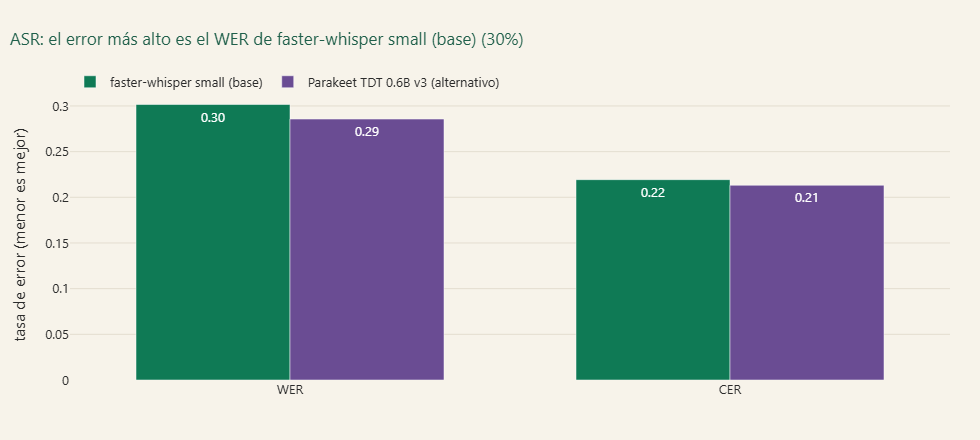

In [6]:
if metricas:
    res = pd.concat(metricas, ignore_index=True)
    graf = res[(res["grupo"] == "TODOS") & res["valor"].notna()]
    peor = graf.loc[graf["valor"].idxmax()]
    fig = px.bar(graf, x="metrica", y="valor", color="modelo", barmode="group", text_auto=".2f",
                 color_discrete_sequence=[VERDE, MORADO],
                 title=f"ASR: el error más alto es el {peor['metrica']} de {peor['modelo']} ({peor['valor']:.0%})",
                 labels={"valor": "tasa de error (menor es mejor)", "metrica": "", "modelo": ""})
    fig.update_layout(legend=dict(orientation="h", y=1.08, x=0), bargap=0.3)
    mostrar(fig, "g4_error_asr")

### Diarización: ¿cuántas voces?

El estudiante anotó cuántas personas distintas habla en cada clip (`n_voces_distintas`); se compara con los
hablantes que detectó la diarización (WeSpeaker + clustering, umbral 0,7).

In [7]:
if ref_audio is not None and not ref_audio.empty and "n_voces_distintas" in ref_audio:
    base = salidas_aud["faster-whisper small (base)"]
    hab = pd.read_csv(RAW / "audio" / "asr_crudo.csv")[["id", "n_hablantes"]]
    dia = ref_audio[["id", "tipo", "n_voces_distintas"]].merge(hab, on="id")
    dia["diferencia"] = dia["n_hablantes"] - dia["n_voces_distintas"]
    display(dia)
    print(f"Clips con el número exacto de voces: {(dia['diferencia'] == 0).sum()} de {len(dia)}; "
          f"sobreestima en {(dia['diferencia'] > 0).sum()}, subestima en {(dia['diferencia'] < 0).sum()}.")
else:
    print("PENDIENTE: falta n_voces_distintas en las referencias de audio.")

,id,tipo,n_voces_distintas,n_hablantes,diferencia
0,clip_002,calle,3,4.0,1.0
1,clip_033,leido_estudio,1,1.0,0.0
2,clip_029,leido_estudio,1,1.0,0.0
3,clip_028,leido_estudio,1,1.0,0.0
4,clip_001,calle,2,2.0,0.0
5,clip_009,evento_publico,2,3.0,1.0
6,clip_006,evento_publico,2,2.0,0.0
7,clip_012,fiesta_patronal,1,1.0,0.0
8,clip_010,fiesta_patronal,2,2.0,0.0
9,clip_015,marcha,3,15.0,12.0


Clips con el número exacto de voces: 7 de 10; sobreestima en 3, subestima en 0.


### Control de calidad de la referencia manual

En los clips de OpenSLR 73 (`leido_estudio`) el dataset trae su propio texto oficial. Comparar la referencia
manual con ese texto mide cuánto se equivocó la persona al transcribir (debería ser casi 0).

In [8]:
if ref_audio is not None and not ref_audio.empty:
    oficial = pd.read_csv(RAW / "audio" / "asr_crudo.csv")[["id", "texto_oficial"]].dropna()
    qc = ref_audio.merge(oficial, on="id")
    if qc.empty:
        print("Ningún clip leído con texto oficial tiene referencia todavía.")
    else:
        qc["WER_manual_vs_oficial"] = parte2.por_caso(qc, "texto_oficial", "texto_referencia", "WER").values
        display(qc[["id", "WER_manual_vs_oficial"]].round(3))

,id,WER_manual_vs_oficial
0,clip_033,0.143
1,clip_029,0.167
2,clip_028,0.091


## 3. OCR: CER y WER contra la referencia manual

**Decisión de método: fragmento fijo.** Los documentos tienen hasta ~50 líneas; la referencia manual cubre las
**primeras 15 líneas** en orden de lectura (o el documento entero si es más corto), con la misma regla para los 10.
Como el OCR devuelve la página completa, se compara la referencia con el tramo de la salida que mejor se le alinea
(`rapidfuzz.fuzz.partial_ratio_alignment` sobre texto normalizado), igual para PaddleOCR y Tesseract. El CER mide
así el reconocimiento dentro del fragmento; no penaliza lo que está fuera ni los errores de orden de lectura fuera
de él. La regla se fijó en `modelos/config_evaluacion.json` antes de escribir referencias y de calcular cualquier
CER de OCR. La muestra se sorteó sobre los 19 documentos actuales (sin capturas propias).

In [9]:
if ref_docs is None or ref_docs.empty:
    print("PENDIENTE: la muestra de 10 documentos ya está sorteada (datos/muestra_evaluacion_documentos.csv), "
          "pero faltan sus referencias manuales. No hay CER/WER de OCR todavía.")
else:
    if falta_docs:
        print(f"AVISO: se evalúa con {len(ref_docs)} de 10 documentos; faltan {falta_docs}.")
    for m in ["CER", "WER"]:
        res, _ = parte2.evaluar(ref_docs, salidas_doc, m, por="tipo", fragmento=True)
        metricas.append(res.assign(modalidad="documento"))
    display(pd.concat([x for x in metricas if (x["modalidad"] == "documento").all()])
            .pivot_table(index=["modelo", "grupo"], columns="metrica", values="valor").round(3))

PENDIENTE: la muestra de 10 documentos ya está sorteada (datos/muestra_evaluacion_documentos.csv), pero faltan sus referencias manuales. No hay CER/WER de OCR todavía.


## 4. Latencia (no necesita referencias)

ASR: RTF = segundos de procesamiento / duración del audio (menos de 1 = más rápido que tiempo real), en la
misma laptop sin GPU y sin contar la carga del modelo. OCR: segundos por página.

In [10]:
base = salidas_aud["faster-whisper small (base)"]
lat = [{"modelo": "faster-whisper small (base)", "casos": len(base), "RTF_mediano": base["rtf"].median()}]
if pk is not None:
    lat.append({"modelo": "Parakeet TDT 0.6B v3 (alternativo)", "casos": len(pk), "RTF_mediano": pk["rtf"].median()})
    comun = base.merge(pk, on="id", suffixes=("_base", "_pk"))
    print(f"En los {len(comun)} clips que procesaron ambos: RTF mediano base {comun['rtf_base'].median():.2f} "
          f"vs Parakeet {comun['rtf_pk'].median():.2f}")
display(pd.DataFrame(lat).round(3))
ocr_lat = pd.DataFrame([{"modelo": k, "documentos": len(v), "seg_por_pagina_mediana": v["segundos"].median(),
                         "seg_total": v["segundos"].sum()} for k, v in salidas_doc.items()])
display(ocr_lat.round(1))

En los 35 clips que procesaron ambos: RTF mediano base 0.54 vs Parakeet 0.21


,modelo,casos,RTF_mediano
0,faster-whisper small (base),35,0.540
1,Parakeet TDT 0.6B v3 (alternativo),35,0.214


,modelo,documentos,seg_por_pagina_mediana,seg_total
0,PaddleOCR (base),19,103.3,2802.6
1,Tesseract (alternativo),19,1.0,34.4


## 5. Extracción con LLM: auditoría humana de 20 casos

10 documentos y 10 audios sorteados (semilla 2026) entre las 32 extracciones existentes; el estudiante juzgó
cada una contra el **texto que recibió el LLM** con los criterios de `trabajo_manual/04_GUIA_auditoria_llm.md`.

In [11]:
acuerdo = None
if aud is None or aud_hechas == 0:
    print("PENDIENTE: la auditoría humana todavía no se ha llenado. No se reporta acuerdo LLM-humano.")
else:
    a = aud.copy()
    crit = ["tema_ok", "resumen_ok", "campos_especificos_ok", "sin_inventos"]
    for c in crit:  # "sí+F12" fue un error de tecleo
        a[c] = a[c].astype(str).str.strip().str.lower().str.replace("+f12", "", regex=False).isin(["si", "sí"])
    # Regla de la guía: completamente correcta = los 4 criterios en "sí" (se aplica la regla, no la columna a mano)
    marcada = a["completamente_correcta"].astype(str).str.strip().str.lower().map({"si": True, "sí": True, "no": False})
    a["completamente_correcta"] = a[crit].all(axis=1)
    distintos = a.loc[marcada.ne(a["completamente_correcta"]), "id"].tolist()
    print("Casos donde la columna escrita a mano no coincidía con la regla (vacía o inconsistente):", distintos)
    acuerdo = a["completamente_correcta"].mean()
    print(f"Extracciones completamente correctas: {int(a['completamente_correcta'].sum())} de {len(a)} = {acuerdo:.0%}"
          + ("" if len(a) == 20 else f"  (AVISO: auditadas {len(a)} de 20)"))
    display(a.groupby("modalidad")[["tema_ok", "resumen_ok", "campos_especificos_ok", "sin_inventos",
                                    "completamente_correcta"]].mean().round(2))
    display(a.loc[~a["completamente_correcta"].astype(bool), ["id", "modalidad", "error_observado"]])

Casos donde la columna escrita a mano no coincidía con la regla (vacía o inconsistente): ['doc_010', 'doc_019', 'doc_011']
Extracciones completamente correctas: 16 de 20 = 80%


,tema_ok,resumen_ok,campos_especificos_ok,sin_inventos,completamente_correcta
modalidad,,,,,
audio,1.0,1.0,0.9,1.0,0.9
documento,1.0,0.9,1.0,0.7,0.7


,id,modalidad,error_observado
0,doc_010,documento,NaN
1,doc_015,documento,resumen agrega edades y filiación que no están...
7,doc_011,documento,"""provisiones"" no aparece en el texto"
11,clip_012,audio,numero_hablantes None; el texto tiene al menos...


## 6. Casos difíciles

Los 3 clips con más error del modelo base (si hay referencias), con lo que se observa en cada uno.

In [12]:
if not detalle_asr.empty:
    b = detalle_asr[detalle_asr["modelo"] == "faster-whisper small (base)"].nlargest(3, "WER")
    alu = pd.read_csv(RAW / "audio" / "asr_crudo.csv")[["id", "condicion", "proporcion_voz", "n_hablantes", "sospechas_alucinacion"]]
    display(b[["id", "tipo", "duracion_seg", "WER"]].merge(alu, on="id").round(3))
else:
    print("PENDIENTE: sin referencias no se pueden ordenar los clips por error.")

,id,tipo,duracion_seg,WER,condicion,proporcion_voz,n_hablantes,sospechas_alucinacion
0,clip_010,fiesta_patronal,98.3,0.935,fiesta_patronal,0.108,2.0,NaN
1,clip_015,marcha,54.3,0.385,marcha,0.930,15.0,"7.2-9.3s: Ya, ya, ya, ya."
2,clip_028,leido_estudio,5.6,0.300,leido_estudio,0.677,1.0,NaN


**Dificultades ya observadas en la Parte 1** (antes de tener referencias, por inspección de las salidas):

- **Música encima de la voz** (`clip_010`, fiesta patronal): el VAD solo encontró voz en ~11 % del clip, así que
  gran parte de lo que se dice no llega al modelo; se espera un WER alto por *borrados*.
- **Muchas voces cortas** (`clip_015`, marcha): la diarización separó hasta 15 "hablantes" con segmentos de ~1 s;
  el número de hablantes no es confiable en grabaciones de multitud.
- **Orden de lectura** (manuscrito de Grau en 3 columnas): PaddleOCR lee bien las palabras pero las mezcla entre
  columnas; por eso ese documento se excluyó de la muestra (regla fijada antes).
- **Reflejos en fotos** (portada de Lampa): el OCR produce ruido y hasta un carácter chino.

## 7. Tabla comparativa y exportación

Costo: los modelos locales no cuestan dinero pero sí tiempo de CPU; Gemini se usó en el nivel gratuito
(límite de 20 pedidos por día, que cortó la extracción). Privacidad: lo local no sale de la laptop; a Gemini
solo se envió texto ya seudonimizado.

In [13]:
res = pd.concat(metricas, ignore_index=True) if metricas else pd.DataFrame(columns=["modelo", "grupo", "metrica", "valor", "modalidad"])
tot = res[res["grupo"] == "TODOS"].pivot_table(index="modelo", columns="metrica", values="valor")
filas = [
    ("PaddleOCR (base)", "OCR", "Apache-2.0", "local, gratis", "local"),
    ("Tesseract (alternativo)", "OCR", "Apache-2.0", "local, gratis", "local"),
    ("faster-whisper small (base)", "ASR", "MIT", "local, gratis", "local"),
    ("Parakeet TDT 0.6B v3 (alternativo)", "ASR", "CC-BY-4.0", "local, gratis", "local"),
    ("Gemini gemini-3.8-flash", "LLM", "propietario (API)", "nivel gratuito, 20 pedidos/día", "nube; solo texto seudonimizado"),
]
comp = pd.DataFrame(filas, columns=["modelo", "tarea", "licencia", "costo", "privacidad"]).set_index("modelo")
comp = comp.join(tot, how="left")
lat_d = {r["modelo"]: f"RTF {r['RTF_mediano']:.2f}" for r in lat}
lat_d.update({r["modelo"]: f"{r['seg_por_pagina_mediana']:.1f} s/página" for _, r in ocr_lat.iterrows()})
comp["latencia"] = comp.index.map(lat_d)
comp.loc["Gemini gemini-3.8-flash", "acuerdo_humano"] = acuerdo
comp = comp.reset_index()
comp.round(3)

,modelo,tarea,licencia,costo,privacidad,CER,WER,latencia,acuerdo_humano
0,PaddleOCR (base),OCR,Apache-2.0,"local, gratis",local,NaN,NaN,103.3 s/página,NaN
1,Tesseract (alternativo),OCR,Apache-2.0,"local, gratis",local,NaN,NaN,1.0 s/página,NaN
2,faster-whisper small (base),ASR,MIT,"local, gratis",local,0.219,0.302,RTF 0.54,NaN
3,Parakeet TDT 0.6B v3 (alternativo),ASR,CC-BY-4.0,"local, gratis",local,0.213,0.286,RTF 0.21,NaN
4,Gemini gemini-3.8-flash,LLM,propietario (API),"nivel gratuito, 20 pedidos/día",nube; solo texto seudonimizado,NaN,NaN,NaN,0.8


In [14]:
Path("datos").mkdir(exist_ok=True)
comp.to_csv("datos/comparacion_modelos.csv", index=False)
if not res.empty:
    out = res[res["valor"].notna()][["modalidad", "modelo", "grupo", "metrica", "valor", "nota"]].copy()
    elegido = (out["grupo"] == "TODOS") & out["modelo"].str.contains("base") & \
              (((out["modalidad"] == "audio") & (out["metrica"] == "WER")) | ((out["modalidad"] == "documento") & (out["metrica"] == "CER")))
    out["elegido"] = elegido
    out.to_csv("datos/metricas.csv", index=False)
    print("datos/metricas.csv", out.shape)
if not detalle_asr.empty:
    tabla.to_csv("datos/comparacion_asr.csv", index=False)
    print("datos/comparacion_asr.csv", tabla.shape)
# extracción del LLM (campos de texto seudonimizado) + acuerdo de la auditoría para el dashboard
ext = pd.read_csv(RAW / "llm" / "extraccion_llm_seud.csv")  # campos re-seudonimizados tras la revisión humana
if aud is not None and aud_hechas:
    ext = ext.merge(a[["id", "completamente_correcta"]].rename(columns={"completamente_correcta": "acuerdo_auditoria"}),
                    on="id", how="left")
ext.to_csv("datos/extraccion_llm.csv", index=False)
print("datos/extraccion_llm.csv", ext.shape)

datos/metricas.csv (24, 7)
datos/comparacion_asr.csv (20, 6)
datos/extraccion_llm.csv (32, 6)


## 8. Qué falta y cómo se completa

Lo que la sección 1 marca como pendiente **no se reemplazó por estimaciones**. Al llenar las plantillas de
`datos/raw/referencias/` (referencias de documentos, clips faltantes, auditoría) basta con volver a ejecutar este
notebook: las métricas se recalculan con la misma regla y la misma muestra.